# 10 时间展开：自己写 RNN 与 BPTT

一次短脉冲过去以后，滤波器里的状态还会逐渐回落。只看当前输入，无法恢复前面留下的这部分影响；计算时需要把一个状态从上一步带到下一步。本课最后训练的就是这样一个滤波过程：每步保留旧状态的一部分，再加入当前输入。

## 1 把时间保留在数组里

先把几条独立记录排成一个数组。B 是序列数，T 是每条序列的时刻数，F 是每时刻的特征数，因而 `X.shape=(B,T,F)`。
`X[b,t]` 取第 b 条序列在时刻 t 的 F 个数；`X[:,t,:]` 取所有序列在同一时刻的输入。后面每次循环取一个这样的时间切片，同时更新 B 条序列的状态。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
torch.set_num_threads(1)
torch.manual_seed(10)
style()

In [3]:
X_shape = np.arange(24).reshape(2, 4, 3)
print('B,T,F:', X_shape.shape)
print('one sequence:', X_shape[0])
print('all sequences at t=1:', X_shape[:, 1, :])

B,T,F: (2, 4, 3)
one sequence: [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
all sequences at t=1: [[ 3  4  5]
 [15 16 17]]


### 练习 r01：取一个时间切片

数组形状为 (2,3,2)，取所有序列在 t=1 的输入。

In [4]:
ex_r01_X = np.arange(12).reshape(2, 3, 2)
ex_r01_slice = None  # TODO
ex_r01_shape = None  # TODO

In [5]:
# 填写上一格后，运行检查。
check('时间切片', ex_r01_slice, [[2, 3], [8, 9]])
check('切片形状', ex_r01_shape, (2, 2))

待填写：时间切片
待填写：切片形状


<details>
<summary>提示</summary>

时间轴是第 1 轴，写 `X[:,1,:]`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r01_X = np.arange(12).reshape(2, 3, 2)
ex_r01_slice = ex_r01_X[:, 1, :]
ex_r01_shape = ex_r01_slice.shape
```

</details>

## 2 同一组参数，连续使用三次

先把输入 $x_t$、状态 $h_t$ 都缩成一个数，t 从 1 编到 3。初态 $h_0=0$。每一步拿到两个量：上一步留下的状态和当前输入，分别乘 a、b 后相加：
$$h_t=a h_{t-1}+b x_t.$$
取 $a=0.5,b=2$，输入依次为 1、2、−1。a、b 在三个时刻保持相同；变化的是输入和传下来的状态。第一步得到 2，第二步会把这个 2 继续带入计算。

In [6]:
x_small = np.array([1., 2., -1.])
a, b = .5, 2.
first_state = a * 0. + b * x_small[0]
print('h_1 =', first_state)
states = [0.]
for x_t in x_small:
    states.append(a * states[-1] + b * x_t)
print('h_0,h_1,h_2,h_3:', states)

h_1 = 2.0
h_0,h_1,h_2,h_3: [0.0, np.float64(2.0), np.float64(5.0), np.float64(0.5)]


### 练习 r02：补齐一次递推

从 h=2 接收 x=2，再接收 x=−1，参数仍为 a=.5、b=2。

In [7]:
ex_r02_h = 2.
ex_r02_second = None  # TODO
ex_r02_third = None  # TODO

In [8]:
# 填写上一格后，运行检查。
check('h_2', ex_r02_second, 5.)
check('h_3', ex_r02_third, .5)

待填写：h_2
待填写：h_3


<details>
<summary>提示</summary>

每步都用刚得到的新状态作为下一步的旧状态。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r02_h = 2.
ex_r02_second = .5 * ex_r02_h + 2. * 2.
ex_r02_third = .5 * ex_r02_second + 2. * (-1.)
```

</details>

把循环沿时间摊开，就能看到状态从哪一步传到哪一步。横向箭头带来旧状态，竖向箭头注入当前输入；三个节点使用同一组 a、b。图中每个状态值都来自刚才的递推。

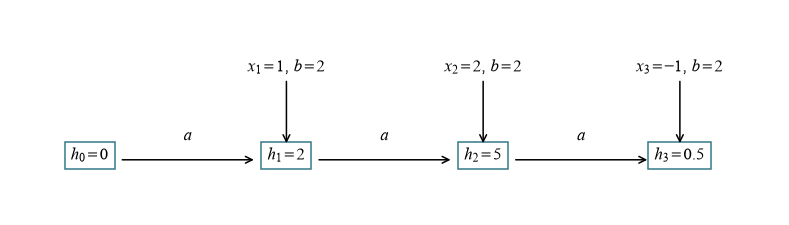

In [9]:
fig, ax = plt.subplots(figsize=(9, 2.4))
for t, h in enumerate(states):
    ax.text(t, 0, f'$h_{t}={h:g}$', ha='center', bbox=dict(fc='white', ec='#37798A'))
    if t:
        ax.annotate('', (t-.15, 0), (t-1+.15, 0), arrowprops=dict(arrowstyle='->'))
        ax.text(t-.5, .14, '$a$', ha='center')
        ax.annotate(f'$x_{t}={x_small[t-1]:g}$, $b=2$', (t, .1), (t, .65), ha='center', arrowprops=dict(arrowstyle='->'))
ax.set(xlim=(-.4, 3.5), ylim=(-.4, 1.1)); ax.axis('off')
show(fig)

## 3 从末端开始回传

三步算出的末端状态为 $h_3=0.5$。现在给它一个目标 $d=1.5$，用 $L=\frac12(h_3-d)^2$ 衡量差距。先考察：如果某一步的状态变动一点，末端损失会怎样变动。这个敏感度记作 $\delta_t=\partial L/\partial h_t$。

从末端开始，$\delta_3=h_3-d=-1$。要回到前一步，就沿着状态箭头穿过一次乘 a 的运算，其局部导数为 $\partial h_t/\partial h_{t-1}=a$：
$$\delta_2=a\delta_3=-0.5,\qquad\delta_1=a\delta_2=-0.25.$$

In [10]:
d = 1.5
delta = np.zeros(3)
delta[2] = states[3] - d
for t in [1, 0]:
    delta[t] = a * delta[t+1]
print('L:', .5 * (states[3] - d) ** 2)
print('dL/dh_1, dL/dh_2, dL/dh_3:', delta)

L: 0.5
dL/dh_1, dL/dh_2, dL/dh_3: [-0.25 -0.5  -1.  ]


### 练习 r03：沿另一条链回传

a=.2，末端 δ3=3，算出 [δ1,δ2,δ3]。

In [11]:
ex_r03_delta = None  # TODO: 从右向左递推
ex_r03_a = .2
ex_r03_last = 3.

In [12]:
# 填写上一格后，运行检查。
check('三个时刻的敏感度', ex_r03_delta, [.12, .6, 3.])

待填写：三个时刻的敏感度


<details>
<summary>提示</summary>

两次相乘分别得到 .6 和 .12，输出按时间正序。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r03_a = .2
ex_r03_last = 3.
ex_r03_delta = np.zeros(3)
ex_r03_delta[-1] = ex_r03_last
for ex_r03_t in [1, 0]:
    ex_r03_delta[ex_r03_t] = ex_r03_a * ex_r03_delta[ex_r03_t+1]
```

</details>

三步用了同一个 a。改变 a 时，它在每个时刻的使用位置都会影响损失，所以要把这些位置的贡献相加：
$$\frac{\partial L}{\partial a}=\sum_{t=1}^3\delta_t h_{t-1},\quad
  \frac{\partial L}{\partial b}=\sum_{t=1}^3\delta_t x_t,\quad
  \frac{\partial L}{\partial x_t}=b\delta_t.$$
各步收到的旧状态为 `[0,2,5]`，对应的敏感度是 `[-.25,-.5,-1]`。相乘后得到 a 的三份贡献 `[0,-1,-5]`，合计为 −6。第一步的旧状态为 0，因此该处对 a 的贡献为 0；另外两处通过同一个参数合并。将 a 增大一个很小的 ε，损失的一阶变化就是 −6ε。

b 的局部乘数则是当前输入。对输入的梯度 $b\delta_t$ 描述改变某个观测会怎样影响损失；优化器根据参数梯度更新 a、b。

In [13]:
contributions_a = delta * np.array(states[:-1])
contributions_b = delta * x_small
print('each use of a:', contributions_a, '; sum:', contributions_a.sum())
print('each use of b:', contributions_b, '; sum:', contributions_b.sum())
print('input sensitivities:', b * delta)

each use of a: [-0. -1. -5.] ; sum: -6.0
each use of b: [-0.25 -1.    1.  ] ; sum: -0.25
input sensitivities: [-0.5 -1.  -2. ]


### 练习 r04：共享权重为什么要相加

按原来的三步轨迹计算 a 的总梯度、b 的总梯度和三个输入梯度。

In [14]:
ex_r04_delta = np.array([-.25, -.5, -1.])
ex_r04_da = None  # TODO
ex_r04_db = None  # TODO
ex_r04_dx = None  # TODO

In [15]:
# 填写上一格后，运行检查。
check('dL/da', ex_r04_da, -6.)
check('dL/db', ex_r04_db, -.25)
check('dL/dx', ex_r04_dx, [-.5, -1., -2.])

待填写：dL/da
待填写：dL/db
待填写：dL/dx


<details>
<summary>提示</summary>

a 乘旧状态 [0,2,5]；b 乘输入 [1,2,−1]；输入局部导数为 b=2。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r04_delta = np.array([-.25, -.5, -1.])
ex_r04_da = np.sum(ex_r04_delta * [0., 2., 5.])
ex_r04_db = np.sum(ex_r04_delta * [1., 2., -1.])
ex_r04_dx = 2. * ex_r04_delta
```

</details>

刚才的相加也能从自动微分里看到。a、b 各创建一次，循环反复使用它们，`backward()` 就会把各个使用位置的贡献累加到同一个 `.grad`。这里采用 float64，把数值核对误差压小。

In [16]:
a_t = torch.tensor(.5, dtype=torch.float64, requires_grad=True)
b_t = torch.tensor(2., dtype=torch.float64, requires_grad=True)
x_torch = torch.tensor([1., 2., -1.], dtype=torch.float64, requires_grad=True)
h = torch.zeros((), dtype=torch.float64)
for value in x_torch:
    h = a_t * h + b_t * value
loss_small = .5 * (h - 1.5) ** 2
loss_small.backward()
check('autograd a', a_t.grad, -6.)
check('autograd input', x_torch.grad, [-.5, -1., -2.])

通过：autograd a
通过：autograd input


In [17]:
def scalar_loss(a_value):
    h_value = 0.
    for value in [1., 2., -1.]:
        h_value = a_value * h_value + 2. * value
    return .5 * (h_value - 1.5) ** 2
epsilon = 1e-6
finite_a = (scalar_loss(.5+epsilon) - scalar_loss(.5-epsilon)) / (2*epsilon)
check('中心差分', finite_a, -6.)

通过：中心差分


### 练习 r05：检查一次有限差分

调用 scalar_loss，在 a=.5 两侧取 ε=1e−5，算中心差分。

In [18]:
ex_r05_eps = 1e-5
ex_r05_gradient = None  # TODO
ex_r05_expected = -6.

In [19]:
# 填写上一格后，运行检查。
check('有限差分梯度', ex_r05_gradient, -6., atol=1e-5)

待填写：有限差分梯度


<details>
<summary>提示</summary>

分子是 L(a+ε)−L(a−ε)，分母是 2ε。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r05_eps = 1e-5
ex_r05_gradient = (scalar_loss(.5+ex_r05_eps)-scalar_loss(.5-ex_r05_eps))/(2*ex_r05_eps)
ex_r05_expected = -6.
```

</details>

## 4 扩展到向量与每步损失

标量状态只有一个存储位置。把它扩展为 H 个分量后，不同分量可以保留不同的历史组合。按行存样本时，$W_x$ 为 `(F,H)`，$W_h$ 为 `(H,H)`：
$$z_t=x_tW_x+h_{t-1}W_h+b,\quad h_t=\tanh z_t.$$
刚才只有最后一步收到目标；后面的滤波预测每步都有损失 $\ell_t$。令 $L=\sum_t\ell_t$，记当前损失带来的敏感度为 $e_t=\partial\ell_t/\partial h_t$，经过 tanh 之前的总敏感度为 $\Delta_t=\partial L/\partial z_t$，则
$$\Delta_t=(e_t+\Delta_{t+1}W_h^\top)\odot(1-h_t^2).$$
括号内的第一项来自当前目标，第二项来自下一步再往后的影响。两条支路先在 $h_t$ 处相加，再乘 tanh 的局部导数 $1-h_t^2$。只有末端目标的例子中，前面时刻的 $e_t$ 都为 0，回传只剩下沿时间边的连乘。若训练使用平均损失，平均系数包含在 $e_t$ 中。

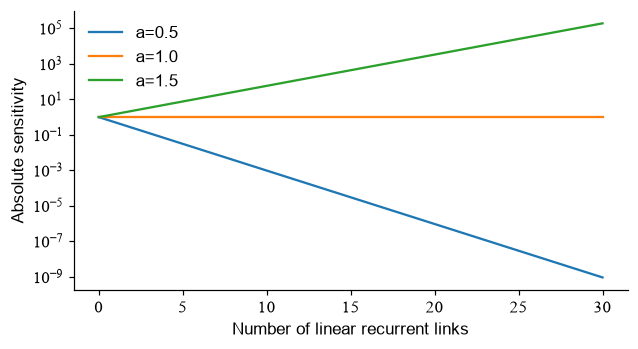

In [20]:
steps = np.arange(31)
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for shared_a in [.5, 1., 1.5]:
    ax.semilogy(steps, np.abs(shared_a ** steps), label=f'a={shared_a}')
ax.set(xlabel='Number of linear recurrent links', ylabel='Absolute sensitivity')
ax.legend(frameon=False)
show(fig)

横轴每增加 1，敏感度就多乘一次 a。a=.5 的曲线逐步衰减，a=1.5 的曲线逐步增长；这些差异来自同一种运算反复出现。向量 RNN 还会乘各步的 tanh 导数与状态权重矩阵。接下来把这条可求导的时间链接到开头的滤波任务。

## 5 合成一批相互独立的序列

每条序列独立生成输入 $u_t$，真实状态按 $y_{t+1}=0.8y_t+0.2u_t$ 更新，$y_0=0$。一次输入对下一状态的贡献为 .2，再往后一时刻还会留下 $.2\times.8$，随后继续衰减。

模型每步只接收 $u_t$，目标是该步更新后的 $y_{t+1}$，因而需要在自己的 h 中保存过去的影响。320 条序列各有 24 步，前 240 条用于训练，后 80 条用于测试；每条序列内部保持时间顺序。

In [21]:
generator = torch.Generator().manual_seed(101)
inputs = torch.randn(320, 24, 1, generator=generator)
target_steps, true_state = [], torch.zeros(320, 1)
for t in range(inputs.shape[1]):
    true_state = .8 * true_state + .2 * inputs[:, t]
    target_steps.append(true_state)
targets = torch.stack(target_steps, dim=1)
train_X, test_X = inputs[:240], inputs[240:]
train_Y, test_Y = targets[:240], targets[240:]

### 练习 r06：给下一时刻预测对齐输入与目标

两条序列各四个时刻。取前三个时刻作输入，后三个时刻作目标，序列轴保持不变。

In [22]:
ex_r06_series = np.array([[0.,1.,2.,3.], [10.,11.,12.,13.]])[:, :, None]
ex_r06_X = None  # TODO
ex_r06_Y = None  # TODO

In [23]:
# 填写上一格后，运行检查。
check('输入时刻', ex_r06_X, np.array([[0.,1.,2.],[10.,11.,12.]])[:,:,None])
check('目标时刻', ex_r06_Y, np.array([[1.,2.,3.],[11.,12.,13.]])[:,:,None])

待填写：输入时刻
待填写：目标时刻


<details>
<summary>提示</summary>

`series[:,:-1,:]` 与 `series[:,1:,:]` 相差一个时刻。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r06_series = np.array([[0.,1.,2.,3.], [10.,11.,12.,13.]])[:, :, None]
ex_r06_X = ex_r06_series[:, :-1, :]
ex_r06_Y = ex_r06_series[:, 1:, :]
```

</details>

`nn.Linear(F,H)` 在内部存 `(H,F)` 的权重，调用时执行 `x @ weight.T + bias`。下面将输入线性、旧状态线性和读出层逐项写在类中。每条新序列从全零状态开始。

In [24]:
class TinyRNN(nn.Module):
    def __init__(self, hidden=8):
        super().__init__()
        self.input_map = nn.Linear(1, hidden)
        self.state_map = nn.Linear(hidden, hidden, bias=False)
        self.readout = nn.Linear(hidden, 1)
    def forward(self, X):
        h = X.new_zeros(X.shape[0], self.state_map.in_features)
        outputs = []
        for t in range(X.shape[1]):
            h = torch.tanh(self.input_map(X[:, t]) + self.state_map(h))
            outputs.append(self.readout(h))
        return torch.stack(outputs, dim=1)

模型内部的 `for t` 负责走完一条时间链；下面的 `for epoch` 负责反复学习同一批训练序列。一次前向保留了全部时刻的计算关系，`loss.backward()` 会沿这些关系回到共享参数，随后优化器统一更新它们。

In [25]:
torch.manual_seed(102)
model = TinyRNN()
optimizer = torch.optim.Adam(model.parameters(), lr=.015)
losses = []
for epoch in range(160):
    optimizer.zero_grad()
    loss = (model(train_X) - train_Y).square().mean()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

independent-sequence MSE: 0.00046562374336645007


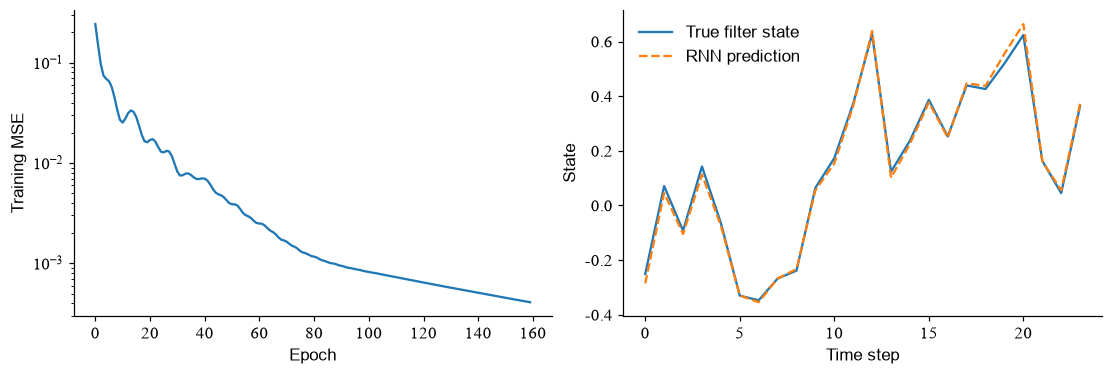

In [26]:
with torch.no_grad():
    prediction = model(test_X)
    test_mse = (prediction-test_Y).square().mean().item()
print('independent-sequence MSE:', test_mse)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout='constrained')
axes[0].semilogy(losses); axes[0].set(xlabel='Epoch', ylabel='Training MSE')
axes[1].plot(test_Y[0, :, 0], label='True filter state')
axes[1].plot(prediction[0, :, 0], '--', label='RNN prediction')
axes[1].set(xlabel='Time step', ylabel='State'); axes[1].legend(frameon=False)
show(fig)

右图取一条独立测试序列，将真实滤波状态和预测放在同一时间轴上。真实曲线中，峰值以后仍然延续的部分来自旧状态的 .8 倍保留；新输入通过 .2 的系数改变当前状态。比较两条曲线的幅度、转折和回落速度，就能看到模型在哪些时刻偏离了这个过程；打印的 MSE 汇总了全部 80 条测试序列。

## 6 自己做一次时间划分实验

当前数据是一批独立序列。若数据来自一条长实验记录，先按时间截出训练段、验证段与未来测试段，再在各段内部做滑动窗口。相邻窗口共享大量采样点，分段边界应先于窗口生成。

只把生成方程中的 0.8 改为 0.98，保持序列数、长度、模型、优化器和训练轮数不变。记录早期输入梯度、测试 MSE 和预测滞后；再单独增加序列长度，比较记忆跨度变化。

## 带着问题读原文

[Pascanu、Mikolov、Bengio：On the difficulty of training RNNs](https://arxiv.org/abs/1211.5063)

找出梯度的时间乘积表示。梯度裁剪改变了哪一个量？用本课的 a=.5 线性链说明：把最大梯度限制住，对已经衰减的梯度有什么影响？